In [1]:
%pip install pymongo
%pip install --upgrade pymongo certifi
import pandas as pd
from pymongo import MongoClient
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import matplotlib.gridspec as gridspec
warnings.filterwarnings('ignore', category=FutureWarning)

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [ ]:
client = MongoClient('mongodb+srv://<username>:<password>@cluster0.mongodb.net/')
db = client['ecom_data_lab']

pipeline_products = [
    {
        '$addFields': {
            'Giảm giá': {
                '$cond': [
                    {'$or': [
                        {'$eq': ['$Giảm giá', None]},
                        {'$eq': ['$Giảm giá', '']}
                    ]},
                    0,
                    {
                        '$cond': [
                            {'$gte': [{'$toDouble': '$Giảm giá'}, 1]},
                            0.99,
                            {'$toDouble': '$Giảm giá'}
                        ]
                    }
                ]
            },
            'Giá_numeric': {'$toDouble': '$Giá'},
            'Đã_bán_numeric': {
                '$cond': [
                    {'$eq': ['$Đã bán', None]},
                    0,
                    {'$toDouble': '$Đã bán'}
                ]
            }
        }
    },
    {
        '$addFields': {
            'Giá_gốc': {
                '$divide': ['$Giá_numeric', {'$subtract': [1, '$Giảm giá']}]
            }
        }
    },
    {
        '$project': {
            '_id': 0,
            'ID Sản phẩm': 1,
            'Tên sản phẩm': 1,
            'Giá': '$Giá_numeric',
            'Giảm giá': 1,
            'Giá_gốc': 1,
            'Đã bán': '$Đã_bán_numeric',
            'Seller ID': 1,
            'Điểm đánh giá': {'$toDouble': '$Điểm đánh giá'},
            'Lượt đánh giá': {'$toDouble': '$Lượt đánh giá'},
            'Danh mục': 1
        }
    }
]

df_shops = pd.DataFrame(list(db['dim_shops'].find({}, {'_id': 0})))

cursor_products = db['fact_products'].aggregate(pipeline_products)
df_products = pd.DataFrame(list(cursor_products))

print("✓ Dữ liệu từ MongoDB đã được tải và xử lý")


✓ Dữ liệu từ MongoDB đã được tải và xử lý


## **BÀI TOÁN PHÂN TÍCH CHUNG**
### **Phân tích toàn diện các yếu tố tác động đến hiệu quả bán hàng trên nền tảng Lazada, dựa trên dữ liệu thu thập trong tháng 3/2026.Tập trung giải quyết 3 khía cạnh cốt lõi:**

### **(1) Chiến lược định giá & Khuyến mãi (tối ưu hóa mức giảm giá theo phân khúc và danh mục).**

### **(2) Uy tín thương hiệu & niềm tin của khách hàng (tác động của loại hình gian hàng, lượng người theo dõi và đánh giá của khách hàng).**

### **(3) Chất lượng vận hành (tỷ lệ phản hồi, giao hàng).**

## **Mục tiêu 1: Phân tích phân bố số lượng bán ra theo 4 phân khúc giá gốc để xác định phân khúc chủ lực.**

### Mục tiêu phân tích 

> Tìm ra phân khúc chiếm lĩnh thị phần lớn nhất (>40%) dựa trên giá gốc. Đồng thời, đối chiếu hành vi mua sắm của khách hàng giữa Shop Thường (cạnh tranh về giá) và LazMall (cạnh tranh bằng uy tín) để kiểm chứng mức phân khúc chủ lực có đúng cho cả 2 loại cửa hàng hay không.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Giá_gốc** *(Numerical/Liên tục)*: Tính bằng công thức Giá / (1 - Giảm giá), giúp phản ánh đúng định vị giá trị thực của sản phẩm trước khi sale.
> - **Phân_khúc_giá** *(Categorical/Phân loại)*: Biến phân nhóm chia Giá_gốc thành 4 khoảng (<100k, 100-300k, 300-500k, >500k).
> - **Đã_bán_numeric** *(Numerical/Liên tục)*: Biến đo lường quy mô sức mua.
> - **Loại_cửa_hàng** *(Categorical/Định danh)*: Trục phân tầng đối chiếu hành vi tiêu dùng.

### Giải thích lý do phù hợp

> Mục tiêu này hỗ trợ giải quyết trực tiếp hai trên ba khía cạnh cốt lõi. 
> Thứ nhất, về **chiến lược định giá**, việc xác định cấu trúc thị phần thực tế theo "Giá gốc" giúp nhà bán hàng nhận diện chính xác dòng tiền đang tập trung ở đâu, từ đó khoanh vùng phân khúc trọng điểm để thiết lập chiến lược giá phù hợp. 
> Thứ hai, về **uy tín thương hiệu**, phân tích đối chiếu giữa Shop Thường và LazMall cho phép kiểm chứng một cách trực diện liệu yếu tố thương hiệu có đủ sức tác động đến hành vi tiêu dùng hay không, đặc biệt trong các phân khúc, nơi rào cản chi tiêu lớn hơn và quyết định mua hàng mang tính cân nhắc nhiều hơn.

### Price Segment Analysis (SMART)

**Cụ thể:**  
Phân tích tổng lượng bán theo 4 phân khúc giá gốc:
- <100k, 100k–300k, 300k–500k, >500k  
So sánh giữa Shop Thường và LazMall  
(Giá gốc = Giá / (1 - Giảm giá))

**Đo lường:**  
- Xác định phân khúc chiếm >40% thị phần  
- So sánh chênh lệch lượng bán ở phân khúc >500k giữa 2 loại shop  

**Khả thi:**  
- Dùng MongoDB (aggregation: tính giá gốc, phân nhóm)  
- Dùng Pandas (groupby) để tổng hợp  

**Liên quan:**  
Giúp chọn chiến lược:
- Shop Thường → cạnh tranh giá  
- LazMall → cạnh tranh uy tín  

**Thời hạn:**  
Dữ liệu đến 03/2026 → dùng cho kế hoạch quý tiếp theo

In [3]:
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")

pipeline_muc_tieu_1 = [
    {
        '$addFields': {
            'Giảm_giá_clean': {
                '$cond': [
                    {'$or': [{'$eq': ['$Giảm giá', None]}, {'$eq': ['$Giảm giá', '']}]},
                    0,
                    {
                        '$cond': [
                            {'$gte': [{'$toDouble': '$Giảm giá'}, 1]},
                            0.99,
                            {'$toDouble': '$Giảm giá'}
                        ]
                    }
                ]
            },
            'Giá_numeric': {'$toDouble': '$Giá'},
            'Đã_bán_numeric': {
                '$cond': [
                    {'$eq': ['$Đã bán', None]},
                    0,
                    {'$toDouble': '$Đã bán'}
                ]
            }
        }
    },
    {
        '$addFields': {
            'Giá_gốc': {
                '$divide': ['$Giá_numeric', {'$subtract': [1, '$Giảm_giá_clean']}]
            }
        }
    },
    {
        '$addFields': {
            'Phân_khúc_giá': {
                '$cond': [
                    {'$lt': ['$Giá_gốc', 100]},
                    'Dưới 100k',
                    {
                        '$cond': [
                            {'$lt': ['$Giá_gốc', 300]},
                            '100k - 300k',
                            {
                                '$cond': [
                                    {'$lt': ['$Giá_gốc', 500]},
                                    '300k - 500k',
                                    'Trên 500k'
                                ]
                            }
                        ]
                    }
                ]
            }
        }
    },
    {
        '$lookup': {
            'from': 'dim_shops',
            'localField': 'Seller ID',
            'foreignField': 'Seller ID',
            'as': 'shop_info'
        }
    },
    {
        '$unwind': {
            'path': '$shop_info',
            'preserveNullAndEmptyArrays': True
        }
    },
    {
        '$project': {
            '_id': 0,
            'Phân_khúc_giá': 1,
            'Đã_bán_numeric': 1,
            'Loại_cửa_hàng': {'$ifNull': ['$shop_info.Loại cửa hàng', 'Không xác định']}
        }
    }
]

products_with_segment = list(db['fact_products'].aggregate(pipeline_muc_tieu_1))

df_obj1 = pd.DataFrame(products_with_segment)

df_summary_total = df_obj1.groupby('Phân_khúc_giá', observed=False)['Đã_bán_numeric'].sum().reset_index()
df_summary_total.columns = ['Phân_khúc_giá', 'Đã_bán_số_lượng']
total_sales = df_summary_total['Đã_bán_số_lượng'].sum()
df_summary_total['Tỷ_trọng_%'] = (df_summary_total['Đã_bán_số_lượng'] / total_sales) * 100

df_shop_type = df_obj1.groupby(['Loại_cửa_hàng', 'Phân_khúc_giá'], observed=False)['Đã_bán_numeric'].sum().reset_index()
df_shop_type.columns = ['Loại_cửa_hàng', 'Phân_khúc_giá', 'Đã_bán_số_lượng']

df_thuong = df_shop_type[df_shop_type['Loại_cửa_hàng'] == 'Shop Thường'].copy()
df_mall = df_shop_type[df_shop_type['Loại_cửa_hàng'] == 'LazMall'].copy()
df_summary_total = df_summary_total.rename(columns={
    'Phân_khúc_giá': 'Phân khúc giá',
    'Đã_bán_số_lượng': 'Đã bán',
    'Tỷ_trọng_%': 'Tỷ trọng (%)'
})
df_thuong = df_thuong.rename(columns={
    'Phân_khúc_giá': 'Phân khúc giá',
    'Đã_bán_số_lượng': 'Đã bán',
    'Loại_cửa_hàng': 'Loại cửa hàng'
})
df_mall = df_mall.rename(columns={
    'Phân_khúc_giá': 'Phân khúc giá',
    'Đã_bán_số_lượng': 'Đã bán',
    'Loại_cửa_hàng': 'Loại cửa hàng'
})

price_order = ['Dưới 100k', '100k - 300k', '300k - 500k', 'Trên 500k']
df_summary_total['Phân khúc giá'] = pd.Categorical(df_summary_total['Phân khúc giá'], categories=price_order, ordered=True)
df_summary_total = df_summary_total.sort_values('Phân khúc giá')

df_thuong['Phân khúc giá'] = pd.Categorical(df_thuong['Phân khúc giá'], categories=price_order, ordered=True)
df_thuong = df_thuong.sort_values('Phân khúc giá')

df_mall['Phân khúc giá'] = pd.Categorical(df_mall['Phân khúc giá'], categories=price_order, ordered=True)
df_mall = df_mall.sort_values('Phân khúc giá')

print("✓ Dữ liệu đã được truy vấn từ MongoDB và xử lý hoàn tất")


✓ Dữ liệu đã được truy vấn từ MongoDB và xử lý hoàn tất


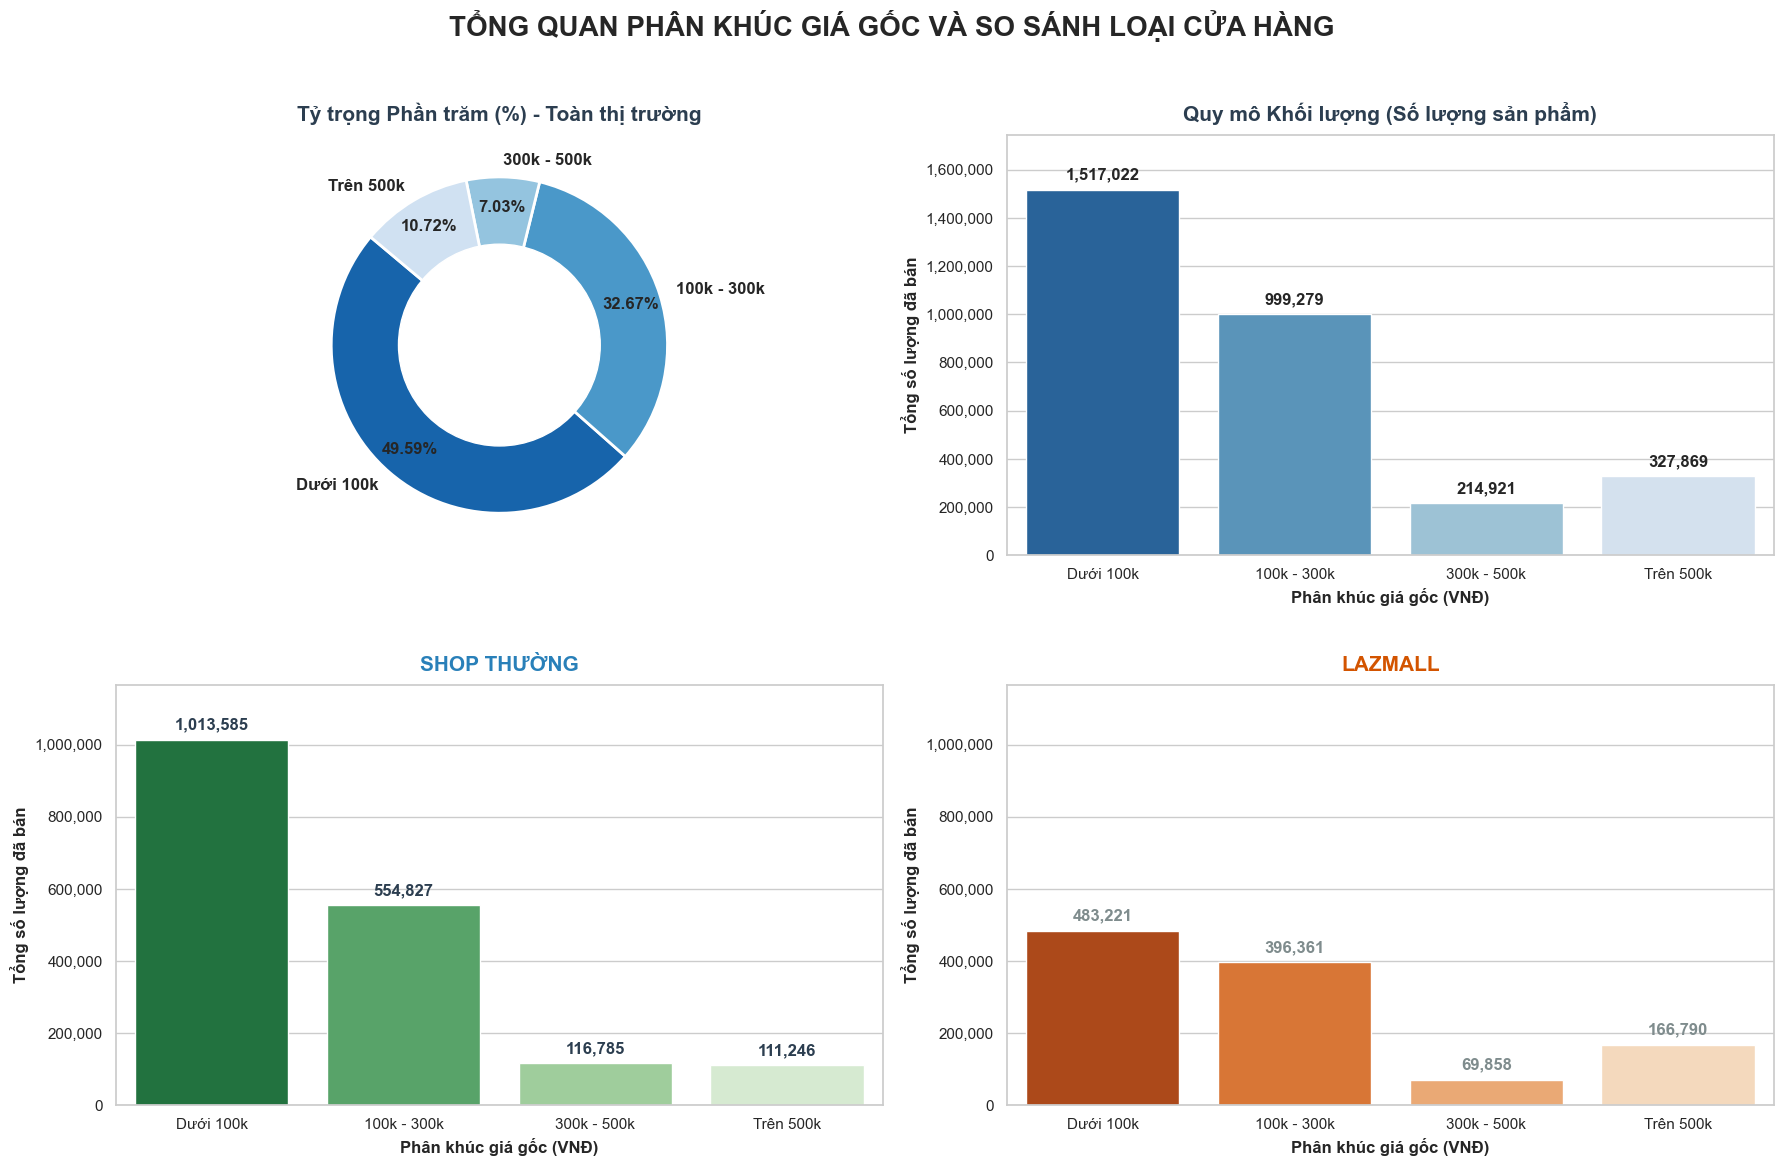

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

fig.suptitle('TỔNG QUAN PHÂN KHÚC GIÁ GỐC VÀ SO SÁNH LOẠI CỬA HÀNG', 
             fontsize=20, fontweight='bold', y=0.97)

colors = sns.color_palette('Blues_r', len(df_summary_total))

# ---------------------------------------------------------
# 1. GÓC TRÊN TRÁI (axes[0, 0]): DONUT CHART - Tỷ trọng %
# ---------------------------------------------------------
axes[0, 0].pie(df_summary_total['Tỷ trọng (%)'], labels=df_summary_total['Phân khúc giá'], 
               autopct='%1.2f%%', startangle=140, colors=colors, pctdistance=0.82,
               textprops={'fontsize': 12, 'fontweight': 'bold'},
               wedgeprops={'edgecolor': 'white', 'linewidth': 2})

# Vẽ vòng tròn trắng ở giữa
centre_circle = plt.Circle((0,0), 0.60, fc='white')
axes[0, 0].add_artist(centre_circle)
axes[0, 0].set_title('Tỷ trọng Phần trăm (%) - Toàn thị trường', fontsize=15, fontweight='bold', color='#2c3e50', pad=10)

# ---------------------------------------------------------
# 2. GÓC TRÊN PHẢI (axes[0, 1]): BAR CHART - Tổng lượng bán
# ---------------------------------------------------------
sns.barplot(data=df_summary_total, x='Phân khúc giá', y='Đã bán', 
            hue='Phân khúc giá', palette='Blues_r', legend=False, ax=axes[0, 1])

axes[0, 1].set_title('Quy mô Khối lượng (Số lượng sản phẩm)', fontsize=15, fontweight='bold', color='#2c3e50', pad=10)
axes[0, 1].set_xlabel('Phân khúc giá gốc (VNĐ)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Tổng số lượng đã bán', fontsize=12, fontweight='bold')
axes[0, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Nới rộng trục Y thêm 15% để có chỗ viết số không bị đứt
max_total = df_summary_total['Đã bán'].max()
axes[0, 1].set_ylim(0, max_total * 1.15)

for i, v in enumerate(df_summary_total['Đã bán']):
    axes[0, 1].text(i, v + (max_total * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

global_max_bottom = max(df_thuong['Đã bán'].max(), df_mall['Đã bán'].max())

# ---------------------------------------------------------
# 3. GÓC DƯỚI TRÁI (axes[1, 0]): SHOP THƯỜNG
# ---------------------------------------------------------
sns.barplot(data=df_thuong, x='Phân khúc giá', y='Đã bán', 
            hue='Phân khúc giá', palette='Greens_r', legend=False, ax=axes[1, 0])

axes[1, 0].set_title('SHOP THƯỜNG', fontsize=15, fontweight='bold', color='#2980b9', pad=10)
axes[1, 0].set_xlabel('Phân khúc giá gốc (VNĐ)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Tổng số lượng đã bán', fontsize=12, fontweight='bold')
axes[1, 0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Set limit dựa trên max chung
axes[1, 0].set_ylim(0, global_max_bottom * 1.15)

for i, v in enumerate(df_thuong['Đã bán']):
    axes[1, 0].text(i, v + (global_max_bottom * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold', color='#2c3e50')

# ---------------------------------------------------------
# 4. GÓC DƯỚI PHẢI (axes[1, 1]): LAZMALL
# ---------------------------------------------------------
sns.barplot(data=df_mall, x='Phân khúc giá', y='Đã bán', 
            hue='Phân khúc giá', palette='Oranges_r', legend=False, ax=axes[1, 1])

axes[1, 1].set_title('LAZMALL', fontsize=15, fontweight='bold', color='#d35400', pad=10)
axes[1, 1].set_xlabel('Phân khúc giá gốc (VNĐ)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Tổng số lượng đã bán', fontsize=12, fontweight='bold')
axes[1, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Set limit dựa trên max chung
axes[1, 1].set_ylim(0, global_max_bottom * 1.15)

for i, v in enumerate(df_mall['Đã bán']):
    axes[1, 1].text(i, v + (global_max_bottom * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold', color='#7f8c8d')

plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3.0)
plt.show()


### **Lý do chọn biểu đồ**
- Donut Chart đo lường Cơ cấu tương đối (%), trong khi Bar Chart đo lường Khối lượng tuyệt đối. Từ đó, định vị chính xác quy mô thực tế của thị trường, tránh rủi ro đánh giá sai nếu chỉ nhìn vào tỷ lệ phần trăm.
- Hai bar chart bên dưới giúp kiểm chứng chéo xu hướng của 2 biểu đồ trên, ngăn chặn sai lầm khi lấy 1 xu hướng áp đặt cho mọi mô hình kinh doanh
### **Nhận xét**
- Dữ liệu cho thấy phân khúc dưới 100k chiếm vị trí đứng đầu với 49.59% thị phần (1,517,022 sản phẩm).
- Nếu tính gộp cả nhóm 100k - 300k, có đến hơn 82% tỷ trọng bán ở mức giá dưới 300k. Phản ánh khách hàng chủ yếu lên sàn thương mại điển tử Lazada để mua các mặt hàng tiêu dùng nhanh, giá trị thấp, ít rủi ro nên họ ra quyết định chốt đơn nhanh.
- Shop Thường: lượng bán tập trung rất lớn ở mức dưới 100k (hơn 1 triệu sản phẩm). Tuy nhiên, biểu đồ tụt dốc nhanh khi giá trị sản phẩm tăng lên do rào cản về rủi ro mua hàng lớn.
- LazMall: Dù tổng sản lượng thấp hơn Shop Thường, nhưng tại phân khúc cao cấp (>500k), LazMall bán ra tới 166,790 sản phẩm, vượt số 111,246 của Shop Thường. Điều này chứng minh: khi mua món hàng đắt tiền, khách hàng thường đến LazMall nhằm đảm bảo chất lượng và chính sách.

### **Kết luận**
- Với các nhà bán hàng mới, ít vốn thì phân khúc dưới 100k (tại Shop Thường) là an toàn và tối ưu nhất. Các mặt hàng bình dân ở nhóm này rất dễ chốt đơn, giúp shop nhanh chóng kéo lượt truy cập, tích lũy đánh giá từ khách hàng và xoay vòng vốn cực kỳ linh hoạt.

- Đối với mục tiêu bán hàng giá trị cao (từ 500k trở lên): Cố gắng hạ giá để cạnh tranh dưới mác Shop Thường không mang lại hiệu quả cao. Thay vào đó, người bán cần tập trung nguồn lực đầu tư vào hình ảnh, nâng cao dịch vụ và đăng ký LazMall. Khi mua đồ đắt tiền, khách hàng sẵn sàng chi tiền cho cửa hàng uy tín và sự an tâm chứ không còn vì ham rẻ.

## **Mục tiêu 2: Đánh giá tác động của mức giảm giá sâu (>30%) đối với nhóm sản phẩm thuộc phân khúc giá cao (trên 500k)**


### Mục tiêu phân tích 

> Đánh giá hiệu quả thực tế của chiến lược "giảm giá sâu" (>30%) đối với nhóm sản phẩm cao cấp (giá gốc > 500k) thông qua việc đối chiếu Số lượng bán và Doanh thu trung bình với nhóm giữ giá (≤30%). Từ đó, kiểm chứng giả thuyết: *Việc sale "sốc" các mặt hàng đắt tiền mang lại sự bùng nổ về sản lượng hay ngược lại, làm bốc hơi dòng tiền và kích hoạt sự hoài nghi của người tiêu dùng?*

### Các trường dữ liệu (Metrics) được sử dụng

> - **Giá_gốc** *(Numerical/Liên tục)*: Biến (Giá / (1 - Giảm giá)), hỗ trợ lấy chuẩn các sản phẩm thuộc phân khúc cao cấp (>500k).
> - **Nhóm_giảm_giá** *(Categorical/Phân loại)*: Biến phân nhóm chia chiến lược khuyến mãi thành 2 loại: "Giảm sâu (>30%)" và "Giảm thấp (≤30%)".
> - **Doanh_thu** *(Numerical/Liên tục)*: Biến phát sinh (Giá * Đã bán), đóng vai trò thước đo tài chính cốt lõi để đánh giá chất lượng dòng tiền mang về.
> - **Số_lượng_SP** *(Numerical/Liên tục)*: Biến đo lường quy mô tiêu thụ để kiểm chứng xem "lượng" có thực sự bù đắp được "giá".

### Giải thích lý do phù hợp

> Thứ nhất, về **chiến lược định giá & khuyến mãi**, việc kết hợp phân tích bảng và biểu đồ phân phối giúp bóc tách rõ ràng rủi ro tài chính khi lạm dụng chiết khấu sâu, đặc biệt trong trường hợp doanh thu có thể sụt giảm nghiêm trọng dù sản lượng tăng. Điều này cung cấp cơ sở định lượng để các nhà bán hàng điều chỉnh chiến lược, tránh tư duy "giảm sâu bù lượng" và bảo vệ biên lợi nhuận. 
> Thứ hai, về **uy tín thương hiệu & niềm tin**, dữ liệu cho thấy ở phân khúc giá cao, việc giảm giá quá mạnh có thể làm suy yếu định vị sản phẩm, khiến khách hàng phát sinh nghi ngờ về chất lượng (hàng tồn, hàng lỗi). Từ đó, định hướng chiến lược hợp lý hơn là chuyển trọng tâm từ giảm giá trực tiếp sang các giá trị gia tăng như dịch vụ, trải nghiệm và tốc độ giao hàng nhằm củng cố niềm tin người tiêu dùng.

### Deep Discount Strategy (SMART)

**Cụ thể:**  
Đánh giá hiệu quả chiến lược giảm giá sâu (>30%) cho sản phẩm cao cấp (>500k)  
So sánh với nhóm giảm ≤30% theo:
- Số lượng bán  
- Doanh thu trung bình  

**Đo lường:**  
- Tỷ trọng mỗi chiến lược  
- Chênh lệch lượng bán  
- Mức giảm doanh thu (≈ 75.51%)  

**Khả thi:**  
- MongoDB: tính giá gốc, doanh thu, lọc >500k, phân nhóm giảm giá  
- Dùng group để tổng hợp  
- Vẽ Boxplot bằng Seaborn  

**Liên quan:**  
Giúp giải quyết bài toán “giảm sâu bù lượng”  
→ Bảo vệ lợi nhuận, tránh giảm giá trị thương hiệu  

**Thời hạn:**  
Dữ liệu đến 03/2026 → dùng cho chiến lược quý tiếp theo

✓ Dữ liệu từ MongoDB:
   Số_lượng_SP   Doanh_thu_TB      Nhóm giảm giá
0         1044  137737.745872    Giảm sâu (>30%)
1         1196  562538.670331  Giảm thấp (<=30%)


C:\Users\luong\AppData\Local\Temp\ipykernel_27608\1879773982.py:220: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


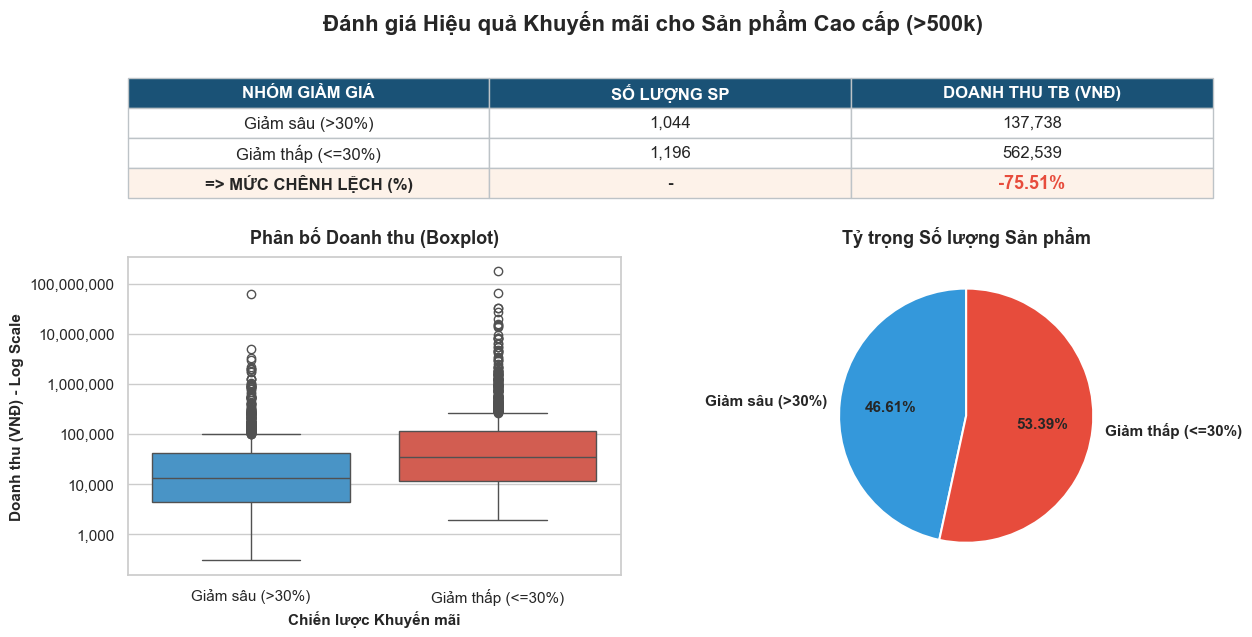

In [5]:
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")

pipeline_muc_tieu_2 = [
    {
        '$addFields': {
            'Giảm_giá_clean': {
                '$cond': [
                    {'$or': [{'$eq': ['$Giảm giá', None]}, {'$eq': ['$Giảm giá', '']}]},
                    0,
                    {
                        '$cond': [
                            {'$gte': [{'$toDouble': '$Giảm giá'}, 1]},
                            0.99,
                            {'$toDouble': '$Giảm giá'}
                        ]
                    }
                ]
            },
            'Giá_numeric': {'$toDouble': '$Giá'},
            'Đã_bán_numeric': {
                '$cond': [
                    {'$eq': ['$Đã bán', None]},
                    0,
                    {'$toDouble': '$Đã bán'}
                ]
            }
        }
    },
    {
        '$addFields': {
            'Giá_gốc': {
                '$divide': ['$Giá_numeric', {'$subtract': [1, '$Giảm_giá_clean']}]
            }
        }
    },
    {
        '$addFields': {
            'Doanh_thu': {
                '$multiply': ['$Giá_numeric', '$Đã_bán_numeric']
            }
        }
    },
    {
        '$match': {
            'Giá_gốc': {'$gt': 500}
        }
    },
    {
        '$addFields': {
            'Nhóm_giảm_giá': {
                '$cond': [
                    {'$gt': ['$Giảm_giá_clean', 0.3]},
                    'Giảm sâu (>30%)',
                    'Giảm thấp (<=30%)'
                ]
            }
        }
    },
    {
        '$group': {
            '_id': '$Nhóm_giảm_giá',
            'Số_lượng_SP': {'$sum': 1},
            'Doanh_thu_TB': {'$avg': '$Doanh_thu'}
        }
    },
    {
        '$project': {
            '_id': 0,
            'Nhóm_giảm_giá': '$_id',
            'Số_lượng_SP': 1,
            'Doanh_thu_TB': 1
        }
    }
]

summary_obj2_raw = list(db['fact_products'].aggregate(pipeline_muc_tieu_2))
summary_obj2 = pd.DataFrame(summary_obj2_raw)

summary_obj2 = summary_obj2.rename(columns={
    'Số_lượng_SP': 'Số_lượng_SP',
    'Doanh_thu_TB': 'Doanh_thu_TB',
    'Nhóm_giảm_giá': 'Nhóm giảm giá'
})

print("✓ Dữ liệu từ MongoDB:")
print(summary_obj2)

sl_giam_sau = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm sâu (>30%)', 'Số_lượng_SP'].values[0]
dt_giam_sau = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm sâu (>30%)', 'Doanh_thu_TB'].values[0]

sl_giam_thap = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm thấp (<=30%)', 'Số_lượng_SP'].values[0]
dt_giam_thap = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm thấp (<=30%)', 'Doanh_thu_TB'].values[0]

chenh_lech_pct = ((dt_giam_sau - dt_giam_thap) / dt_giam_thap) * 100
fig = plt.figure(figsize=(14, 6.5))
fig.suptitle('Đánh giá Hiệu quả Khuyến mãi cho Sản phẩm Cao cấp (>500k)', 
             fontsize=16, fontweight='bold', y=0.98)

gs = gridspec.GridSpec(2, 2, height_ratios=[0.8, 2], hspace=0.25)

# Tạo các vùng vẽ (Axes)
ax_table = fig.add_subplot(gs[0, :])
ax_box = fig.add_subplot(gs[1, 0])
ax_pie = fig.add_subplot(gs[1, 1])
pipeline_boxplot = [
    {
        '$addFields': {
            'Giảm_giá_clean': {
                '$cond': [
                    {'$or': [{'$eq': ['$Giảm giá', None]}, {'$eq': ['$Giảm giá', '']}]},
                    0,
                    {
                        '$cond': [
                            {'$gte': [{'$toDouble': '$Giảm giá'}, 1]},
                            0.99,
                            {'$toDouble': '$Giảm giá'}
                        ]
                    }
                ]
            },
            'Giá_numeric': {'$toDouble': '$Giá'},
            'Đã_bán_numeric': {'$toDouble': '$Đã bán'}
        }
    },
    {
        '$addFields': {
            'Giá_gốc': {
                '$divide': ['$Giá_numeric', {'$subtract': [1, '$Giảm_giá_clean']}]
            },
            'Doanh_thu': {
                '$multiply': ['$Giá_numeric', {'$toDouble': '$Đã bán'}]
            }
        }
    },
    {
        '$match': {
            'Giá_gốc': {'$gt': 500}
        }
    },
    {
        '$addFields': {
            'Nhóm_giảm_giá': {
                '$cond': [
                    {'$gt': ['$Giảm_giá_clean', 0.3]},
                    'Giảm sâu (>30%)',
                    'Giảm thấp (<=30%)'
                ]
            }
        }
    },
    {
        '$project': {
            '_id': 0,
            'Nhóm_giảm_giá': 1,
            'Doanh_thu': 1
        }
    }
]

df_high_price = pd.DataFrame(list(db['fact_products'].aggregate(pipeline_boxplot)))
df_high_price = df_high_price.rename(columns={'Nhóm_giảm_giá': 'Nhóm giảm giá'})

# ---------------------------------------------------------
# PHẦN 1 (TRÊN CÙNG): VẼ BIỂU ĐỒ BẢNG (TABLE)
# ---------------------------------------------------------
ax_table.axis('off')
table_data = [
    ['Giảm sâu (>30%)', f"{sl_giam_sau:,.0f}", f"{dt_giam_sau:,.0f}"],
    ['Giảm thấp (<=30%)', f"{sl_giam_thap:,.0f}", f"{dt_giam_thap:,.0f}"],
    ['=> MỨC CHÊNH LỆCH (%)', '-', f"{chenh_lech_pct:,.2f}%"]
]
columns = ['NHÓM GIẢM GIÁ', 'SỐ LƯỢNG SP', 'DOANH THU TB (VNĐ)']

table = ax_table.table(cellText=table_data, colLabels=columns, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.8) 

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#bdc3c7')
    if row == 0:
        cell.set_facecolor('#1A5276')
        cell.set_text_props(color='white', weight='bold')
    elif row == 3:
        cell.set_facecolor('#fdf2e9')
        cell.set_text_props(weight='bold')
        if col == 2: 
            text_color = '#e74c3c' if chenh_lech_pct < 0 else '#2ecc71'
            cell.set_text_props(color=text_color, weight='bold', fontsize=13)
    else:
        cell.set_facecolor('#ffffff')

# ---------------------------------------------------------
# PHẦN 2 (DƯỚI TRÁI): BOXPLOT - PHÂN BỐ DOANH THU
# ---------------------------------------------------------
order_list = ['Giảm sâu (>30%)', 'Giảm thấp (<=30%)']
sns.boxplot(data=df_high_price, x='Nhóm giảm giá', y='Doanh_thu', 
            palette=['#3498db', '#e74c3c'], order=order_list, ax=ax_box)

ax_box.set_title('Phân bố Doanh thu (Boxplot)', fontsize=13, fontweight='bold', pad=10)
ax_box.set_xlabel('Chiến lược Khuyến mãi', fontsize=11, fontweight='bold')
ax_box.set_yscale('log')
ax_box.set_ylabel('Doanh thu (VNĐ) - Log Scale', fontsize=11, fontweight='bold')
ax_box.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,.0f}".format(int(x))))

# ---------------------------------------------------------
# PHẦN 3 (DƯỚI PHẢI): PIE CHART - TỶ TRỌNG SỐ LƯỢNG
# ---------------------------------------------------------
sizes = [sl_giam_sau, sl_giam_thap]
labels = ['Giảm sâu (>30%)', 'Giảm thấp (<=30%)']

ax_pie.pie(sizes, labels=labels, autopct='%1.2f%%', startangle=90, 
           colors=['#3498db', '#e74c3c'],
           textprops={'fontsize': 11, 'fontweight': 'bold'},
           wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})

ax_pie.set_title('Tỷ trọng Số lượng Sản phẩm', fontsize=13, fontweight='bold', pad=10)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### **Lý do chọn biểu đồ**
- Pie Chart: Trực quan hóa tỷ trọng, giúp xác định xem các nhà bán hàng hiện tại đang ưu tiên chiến lược nào.
- Table: Diễn đạt chính xác sự chênh lệch bằng những con số thực tế về Số lượng bán và Doanh thu trung bình.
- Boxplot: Hộp phân bố và đường trung vị chứng minh cho sự vững chắc của doanh thu mà không bị ảnh hưởng bởi một vài đơn hàng ngoại.
### **Nhận xét**
- Biểu đồ Pie Chart cho thấy các sản phẩm trên 500k có hai hướng giảm giá khá cân bằng: khoảng 46.61% giảm sâu và 53.39% giảm nhẹ.
- Kỳ vọng là "giảm giá sâu để đổi lấy số lượng lớn". Tuy nhiên, dữ liệu chỉ ra sự thất bại toàn diện của chiến lược này: Số lượng sản phẩm bán ra ở nhóm giảm sâu còn thấp hơn nhóm giảm ít (1,044 so với 1,196).
- Kéo theo doanh thu trung bình của nhóm giảm sâu bốc hơi tới 75.51%
- Nhìn sang biểu đồ Boxplot, vị trí thân hộp và đường trung vị của nhóm "Giảm thấp" nằm ở vị thế cao hơn. Dữ liệu này khẳng định rằng: Nhóm giữ giá tốt không chỉ bán được nhiều hàng hơn, mà dòng tiền mang về cũng chất lượng và ổn định hơn hẳn.

### **Kết luận**
- Dữ liệu chứng minh hành vi mua sắm hàng cao cấp (>500k) hoàn toàn khác biệt với hàng giá rẻ. Ở phân khúc này, quyết định chốt đơn dựa trên nhu cầu thực tế và uy tín cửa hàng. Khi một món đồ đắt tiền bị sale "sốc" (>30%), nó lập tức kích hoạt sự hoài nghi của khách hàng: "Liệu đây có phải hàng tồn kho cận date?", "Sản phẩm bị lỗi?", hay "Shop đang đôn giá ảo rồi sale?".

- Thay vì hy sinh lợi nhuận vào các voucher giảm giá trực tiếp, ngân sách nên được chuyển hướng sang các dịch vụ gia tăng tạo uy tín, chất lượng như: Đóng gói cao cấp, Freeship hỏa tốc, hoặc các chính sách bảo hành/đổi trả 1-1 dài hạn.   

## **Mục tiêu 3: Phân nhóm các mức giảm giá thành 5 khoảng để xác định "khoảng giảm giá tối ưu"**

### Mục tiêu phân tích 

> Phân rã dữ liệu thành 5 biên độ chiết khấu (0-10%, 10-20%, 20-30%, 30-50%, >50%) để dò tìm "Điểm ngọt" (Sweet Spot) mang lại dòng tiền cao nhất. Đồng thời, đối chiếu hiệu quả tài chính này với mật độ phân bổ sản phẩm thực tế là sự lệch pha trong tư duy định giá của đám đông nhà bán hàng trên sàn.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Doanh_thu** *(Numerical/Liên tục)*: Biến phát sinh được tạo ra trong Pandas bằng phép tính Giá * Đã bán, đóng vai trò thước đo tài chính cốt lõi.
> - **Khoảng_giảm_giá** *(Categorical/Phân loại)*: Biến phân nhóm sử dụng hàm `pd.cut` để chia nhỏ mức chiết khấu thành 5 cấp bậc đo lường.
> - **Doanh_thu_TB** *(Numerical/Liên tục)*: Giá trị trung bình được tổng hợp (hàm `groupby`), dùng làm trục tọa độ cho Line Chart để dò tìm "đỉnh" doanh thu.
> - **Số_lượng_SP** *(Numerical/Liên tục)*: Tần suất phân bổ (hàm `count`), dùng cho Bar Chart để phác họa thực trạng áp dụng chiến lược giá của toàn thị trường.

### Giải thích lý do phù hợp

> **chiến lược định giá & khuyến mãi**. Việc xác định "điểm ngọt" tối ưu về mặt doanh thu cung cấp một đáp án định lượng rõ ràng cho bài toán thiết lập mức chiết khấu hiệu quả. Đồng thời, khi đặt song song hiệu quả tài chính với mật độ phân bổ sản phẩm theo từng mức giảm giá, phân tích này giúp phát hiện sự lệch pha trong hành vi của thị trường — nơi một lượng lớn sản phẩm vẫn đang áp dụng các mức chiết khấu kém hiệu quả. Từ đó, cung cấp cơ sở thực nghiệm để các nhà bán hàng điều chỉnh chiến lược, giảm thiểu lãng phí ngân sách khuyến mãi và tối ưu hóa dòng tiền cũng như biên lợi nhuận.

### Discount Sweet Spot (SMART)

**Cụ thể:**  
Phân tích 5 mức giảm giá:
- 0–10%, 10–20%, 20–30%, 30–50%, >50%  
→ So sánh doanh thu trung bình để tìm “điểm ngọt”  

**Đo lường:**  
- Xác định mức giảm giá tối ưu (≈ 263,974 VNĐ)  
- Số sản phẩm định giá sai (giảm >30% ~ 3,000+)  

**Khả thi:**  
- Pandas: làm sạch dữ liệu giảm giá  
- Tạo doanh thu = Giá * Đã bán  
- Dùng `pd.cut` để chia nhóm  
- `groupby` để tính số lượng và doanh thu  

**Liên quan:**  
Giúp tránh lạm dụng giảm giá  
→ Bảo vệ lợi nhuận, tối ưu chiến lược pricing  

**Thời hạn:**  
Dữ liệu đến 04/2026 → áp dụng ngay cho kỳ kinh doanh tiếp theo

In [6]:
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")
df_obj3 = df_products.copy()

df_obj3['Giảm giá'] = df_obj3['Giảm giá'].fillna(0).apply(lambda x: 0.99 if pd.to_numeric(x, errors='coerce') >= 1 else pd.to_numeric(x, errors='coerce'))
df_obj3['Giá'] = pd.to_numeric(df_obj3['Giá'], errors='coerce')
df_obj3['Đã bán'] = pd.to_numeric(df_obj3['Đã bán'], errors='coerce').fillna(0)

# Tính Doanh thu ước tính (Giá hiện tại * Đã bán)
df_obj3['Doanh thu'] = df_obj3['Giá'] * df_obj3['Đã bán']

bins = [-0.01, 0.10, 0.20, 0.30, 0.50, np.inf]
labels = ['0 - 10%', '10% - 20%', '20% - 30%', '30% - 50%', '> 50%']

df_obj3['Khoảng giảm giá'] = pd.cut(df_obj3['Giảm giá'], bins=bins, labels=labels)

summary_obj3 = df_obj3.groupby('Khoảng giảm giá', observed=False).agg(
    Số_lượng_SP=('ID Sản phẩm', 'count'),
    Doanh_thu_TB=('Doanh thu', 'mean')
).reset_index()

sweet_spot = summary_obj3.loc[summary_obj3['Doanh_thu_TB'].idxmax()]

print("="*60)
print(f"🎯 KẾT QUẢ TÌM KIẾM 'SWEET SPOT' (KHOẢNG TỐI ƯU):")
print(f"- Khoảng giảm giá mang lại doanh thu TB cao nhất: {sweet_spot['Khoảng giảm giá']}")
print(f"- Doanh thu TB đạt: {sweet_spot['Doanh_thu_TB']:,.0f} VNĐ")
print("="*60)

def style_summary_obj3(df):
    styles = [
        {'selector': 'th', 'props': [('background-color', '#1A5276'), ('color', '#FFFFFF'), ('font-weight', 'bold'), ('text-transform', 'uppercase'), ('text-align', 'center'), ('padding', '12px 20px'), ('border-bottom', '3px solid #0E2B3D')]},
        {'selector': 'td', 'props': [('background-color', '#FFFFFF'), ('color', '#2C3E50'), ('text-align', 'center'), ('padding', '10px 20px'), ('border-bottom', '1px solid #EAEDED')]},
        {'selector': 'tr:hover td', 'props': [('background-color', '#EBF5FB'), ('color', '#1A5276'), ('font-weight', 'bold')]}
    ]
    return df.style.set_table_styles(styles).format({'Số_lượng_SP': '{:,.0f}', 'Doanh_thu_TB': '{:,.0f}'}).hide(axis='index')

print("\nBẢNG THỐNG KÊ DOANH THU THEO 5 KHOẢNG GIẢM GIÁ:")
display(style_summary_obj3(summary_obj3))

🎯 KẾT QUẢ TÌM KIẾM 'SWEET SPOT' (KHOẢNG TỐI ƯU):
- Khoảng giảm giá mang lại doanh thu TB cao nhất: 0 - 10%
- Doanh thu TB đạt: 263,974 VNĐ

BẢNG THỐNG KÊ DOANH THU THEO 5 KHOẢNG GIẢM GIÁ:


Khoảng giảm giá,Số_lượng_SP,Doanh_thu_TB
0 - 10%,"2,296","263,974"
10% - 20%,631,"146,417"
20% - 30%,"1,042","101,281"
30% - 50%,"2,086","88,920"
> 50%,966,"56,328"


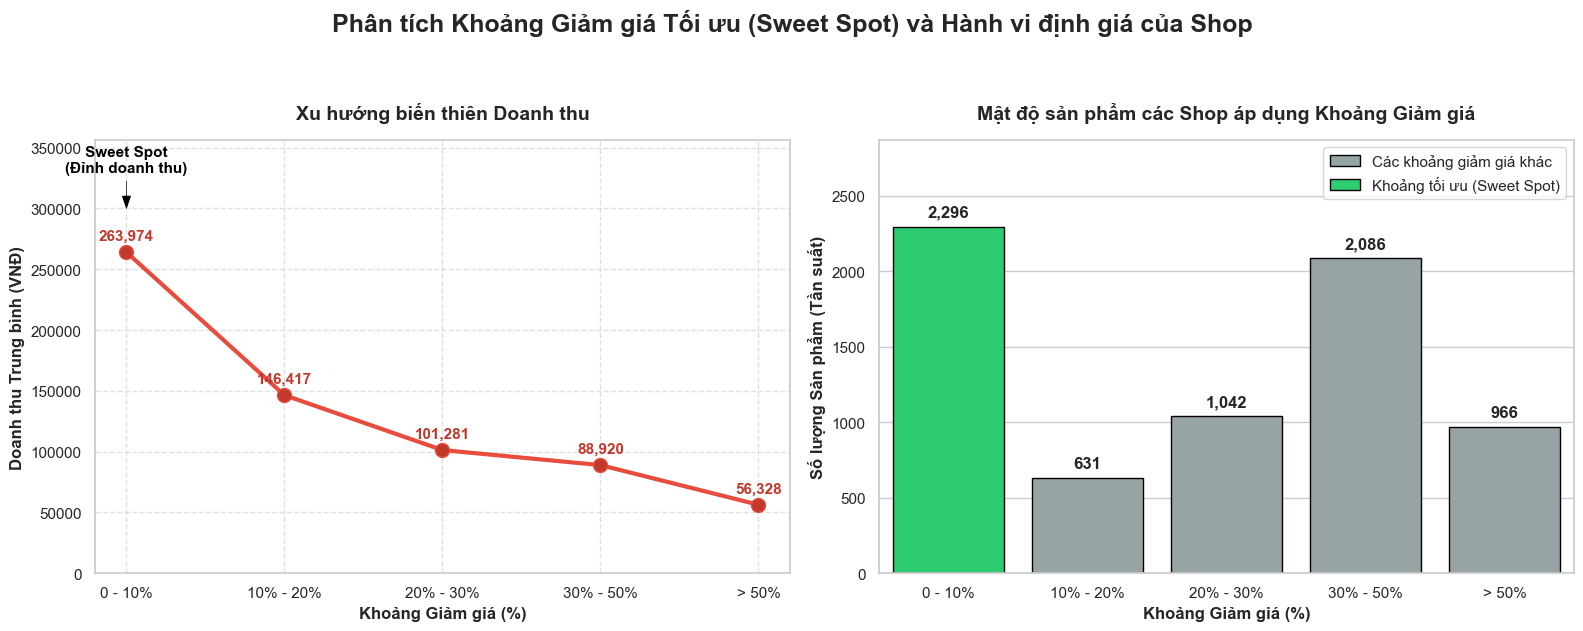

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Phân tích Khoảng Giảm giá Tối ưu (Sweet Spot) và Hành vi định giá của Shop', 
             fontsize=18, fontweight='bold', y=1.05)

# ---------------------------------------------------------
# ĐỒ THỊ 1 (BÊN TRÁI): LINE CHART KÈM MARKER (Đường cong doanh thu)
# ---------------------------------------------------------
axes[0].plot(summary_obj3['Khoảng giảm giá'].astype(str), summary_obj3['Doanh_thu_TB'], 
             color='#e74c3c', marker='o', linewidth=3, markersize=10, markerfacecolor='#c0392b')

axes[0].set_title('Xu hướng biến thiên Doanh thu', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Khoảng Giảm giá (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Doanh thu Trung bình (VNĐ)', fontsize=12, fontweight='bold')
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:.0f}".format(int(x))))
axes[0].grid(True, linestyle='--', alpha=0.6)

max_doanhthu = summary_obj3['Doanh_thu_TB'].max()
axes[0].set_ylim(0, max_doanhthu * 1.35)

for i, v in enumerate(summary_obj3['Doanh_thu_TB']):
    axes[0].text(i, v + (max_doanhthu * 0.03), f'{v:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#c0392b')

max_idx = summary_obj3['Doanh_thu_TB'].idxmax()
axes[0].annotate('Sweet Spot\n(Đỉnh doanh thu)', 
                 xy=(max_idx, max_doanhthu * 1.12),
                 xytext=(max_idx, max_doanhthu * 1.25), 
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                 ha='center', fontsize=11, fontweight='bold', color='black')

# ---------------------------------------------------------
# ĐỒ THỊ 2 (BÊN PHẢI): HISTOGRAM (Phân bố số lượng sản phẩm)
# ---------------------------------------------------------
sns.barplot(data=summary_obj3, x='Khoảng giảm giá', y='Số_lượng_SP', color='#95a5a6', edgecolor='black', ax=axes[1])

axes[1].patches[max_idx].set_facecolor('#2ecc71')

axes[1].set_title('Mật độ sản phẩm các Shop áp dụng Khoảng Giảm giá', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Khoảng Giảm giá (%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Số lượng Sản phẩm (Tần suất)', fontsize=12, fontweight='bold')
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:.0f}".format(int(x))))

max_sp = summary_obj3['Số_lượng_SP'].max()
axes[1].set_ylim(0, max_sp * 1.25)

for i, v in enumerate(summary_obj3['Số_lượng_SP']):
    axes[1].text(i, v + (max_sp * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#95a5a6', edgecolor='black', label='Các khoảng giảm giá khác'),
    Patch(facecolor='#2ecc71', edgecolor='black', label='Khoảng tối ưu (Sweet Spot)')
]
axes[1].legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()



### **Lý do chọn biểu đồ**
- Để xác định chính xác Sweet Spot trong chiến lược giá, ta cần đối chiếu giữa hiệu quả tài chính và hành vi thực tế của thị trường.
- Line Chart: Vẽ ra quỹ đạo của dòng tiền. Nó theo dõi sự biến thiên của Doanh thu trung bình qua từng mốc giảm giá để chỉ rõ vùng doanh thu lý tưởng.
- Bar Chart: Thể hiện mật độ phân bổ sản phẩm theo từng biên độ giảm giá, qua đó làm nổi bật sự "lệch pha" giữa chiến lược thiết lập giá của đa số các shop và điểm tối ưu thực tế.
### **Nhận xét**
- Biểu đồ đường (Line Chart) cho thấy đường doanh thu là một dốc trượt thẳng. Mốc 0 - 10% chính là "Sweet Spot" mang lại doanh thu trung bình đỉnh điểm (đạt 263,974 VNĐ).
- Ngay khi vượt qua khoảng giảm 10%, doanh thu lập tức bốc hơi gần một nửa (rơi xuống 146,417 VNĐ ở mốc 10-20%). Tới khi shop giảm trên 50%, doanh thu chạm đáy chỉ còn vỏn vẹn 56,328 VNĐ. Điều này khẳng định: Càng giảm sâu, dòng tiền mang về càng cạn kiệt.
- Đáng chú ý là biểu đồ Bar Chart lại chỉ ra một nghịch lý trong chiến lược định giá của các shop. Mặc dù 0-10% là mốc tối ưu mang lại dòng tiền tốt nhất, số lượng sản phẩm áp dụng mức này (2,296) lại không chênh lệch nhiều so với nhóm giảm sâu 30-50% (2,086 sản phẩm). Thậm chí, vẫn có gần 1,000 sản phẩm đang giảm trên 50%. Sự phân bổ này phản ánh một thực trạng: nhiều nhà bán hàng vẫn giữ quan điểm phải có "giảm giá khủng" mới thu hút được khách hàng, dẫn đến việc hy sinh biên lợi nhuận không cần thiết.

### **Kết luận**
- Việc cố gắng áp dụng mức giảm trên 30% (thậm chí >50%) với hy vọng bán được số lượng lớn là một chiến lược kém hiệu quả vì mang lại doanh thu thấp.
- Dữ liệu chứng minh khoảng chiết khấu 0-10% (tối đa không quá 20%) là mức lý tưởng nhất để cân bằng giữa việc kích thích tâm lý người mua và bảo vệ biên lợi nhuận. Các nhà bán hàng nên dùng khoảng giảm này như một Voucher ưu đãi để khách hàng chốt đơn, thay vì tạo ra các mức giá ảo quá lớn. Phần biên lợi nhuận giữ lại được từ việc thu hẹp tỷ lệ giảm giá nên được dùng để chạy quảng cáo tăng hiển thị hoặc nâng cấp dịch vụ, tạo ra lợi thế cạnh tranh bền vững hơn.

## **Mục tiêu 4: Tính toán hệ số tương quan (Correlation) giữa tỷ lệ giảm giá (%) và lượng bán ra.**

### 1. Mục tiêu phân tích
> Tính toán hệ số tương quan Pearson ($r$) giữa "Tỷ lệ giảm giá" và "Lượng bán ra" kết hợp trực quan hóa đa chiều (Heatmap, Scatter, Hexbin) để kiểm định mối quan hệ tuyến tính. Từ đó, chứng minh bằng toán học giả thuyết: *Giảm giá càng sâu có thực sự mang lại sự bùng nổ về sản lượng bán ra như lầm tưởng của đa số nhà bán hàng?*

### 2. Các trường dữ liệu (Metrics) được sử dụng
> - **Giảm_giá_clean (%)** *(Numerical)*: Tỷ lệ chiết khấu đã được làm sạch và chuẩn hóa (quy về % thực tế).
> - **Đã_bán_numeric** *(Numerical)*: Khối lượng sản phẩm bán ra, biến số phụ thuộc cần đo lường.
> - **Hệ số tương quan ($r$)**: Chỉ số thống kê đo lường mức độ liên kết tuyến tính giữa 2 biến trên (kết quả trích xuất $r = 0.0136$).
> - **Khoảng_giảm_giá** *(Categorical)*: Biến phân nhóm để vẽ Bar Chart đối chiếu lượng bán trung bình ở từng mốc, giúp "phiên dịch" số thống kê ra ngôn ngữ kinh doanh.

### 3. Sự phù hợp với bài toán chung (Relevance)
> Mục tiêu này đóng vai trò kết luận cho khía cạnh số 1 của dự án (Chiến lược định giá & Khuyến mãi). Bằng việc cung cấp bằng chứng định lượng ($r \approx 0$), phân tích đập tan triệt để lầm tưởng "giảm sâu bù lượng". Kết quả này là căn cứ vững chắc nhất để thuyết phục các shop dừng lãng phí ngân sách vào các mức sale >30% và luân chuyển vốn sang các kênh tăng tỷ lệ chuyển đổi thực chất hơn.

### Discount vs Sales Correlation (SMART)

**Cụ thể:**  
Tính hệ số tương quan Pearson (r) giữa:
- Tỷ lệ giảm giá  
- Lượng bán ra  
→ Kết hợp biểu đồ để kiểm tra mối quan hệ  

**Đo lường:**  
- Hệ số tương quan rất thấp (r ≈ 0.0136)  
- Chênh lệch lượng bán nhỏ (~ +41 sản phẩm/shop)  
giữa mức giảm thấp và giảm sâu  

**Khả thi:**  
- MongoDB: làm sạch và lấy dữ liệu  
- Pandas: dùng `.corr()`  
- Seaborn/Matplotlib: vẽ Heatmap, Scatter, Hexbin, Bar  

**Liên quan:**  
Chứng minh “giảm sâu không giúp tăng bán đáng kể”  
→ Tránh lãng phí ngân sách khuyến mãi  

**Thời hạn:**  
Dữ liệu đến 04/2026 → áp dụng ngay cho kế hoạch tháng tới

- Hệ số tương quan (r) giữa Giảm giá và Đã bán: 0.0136


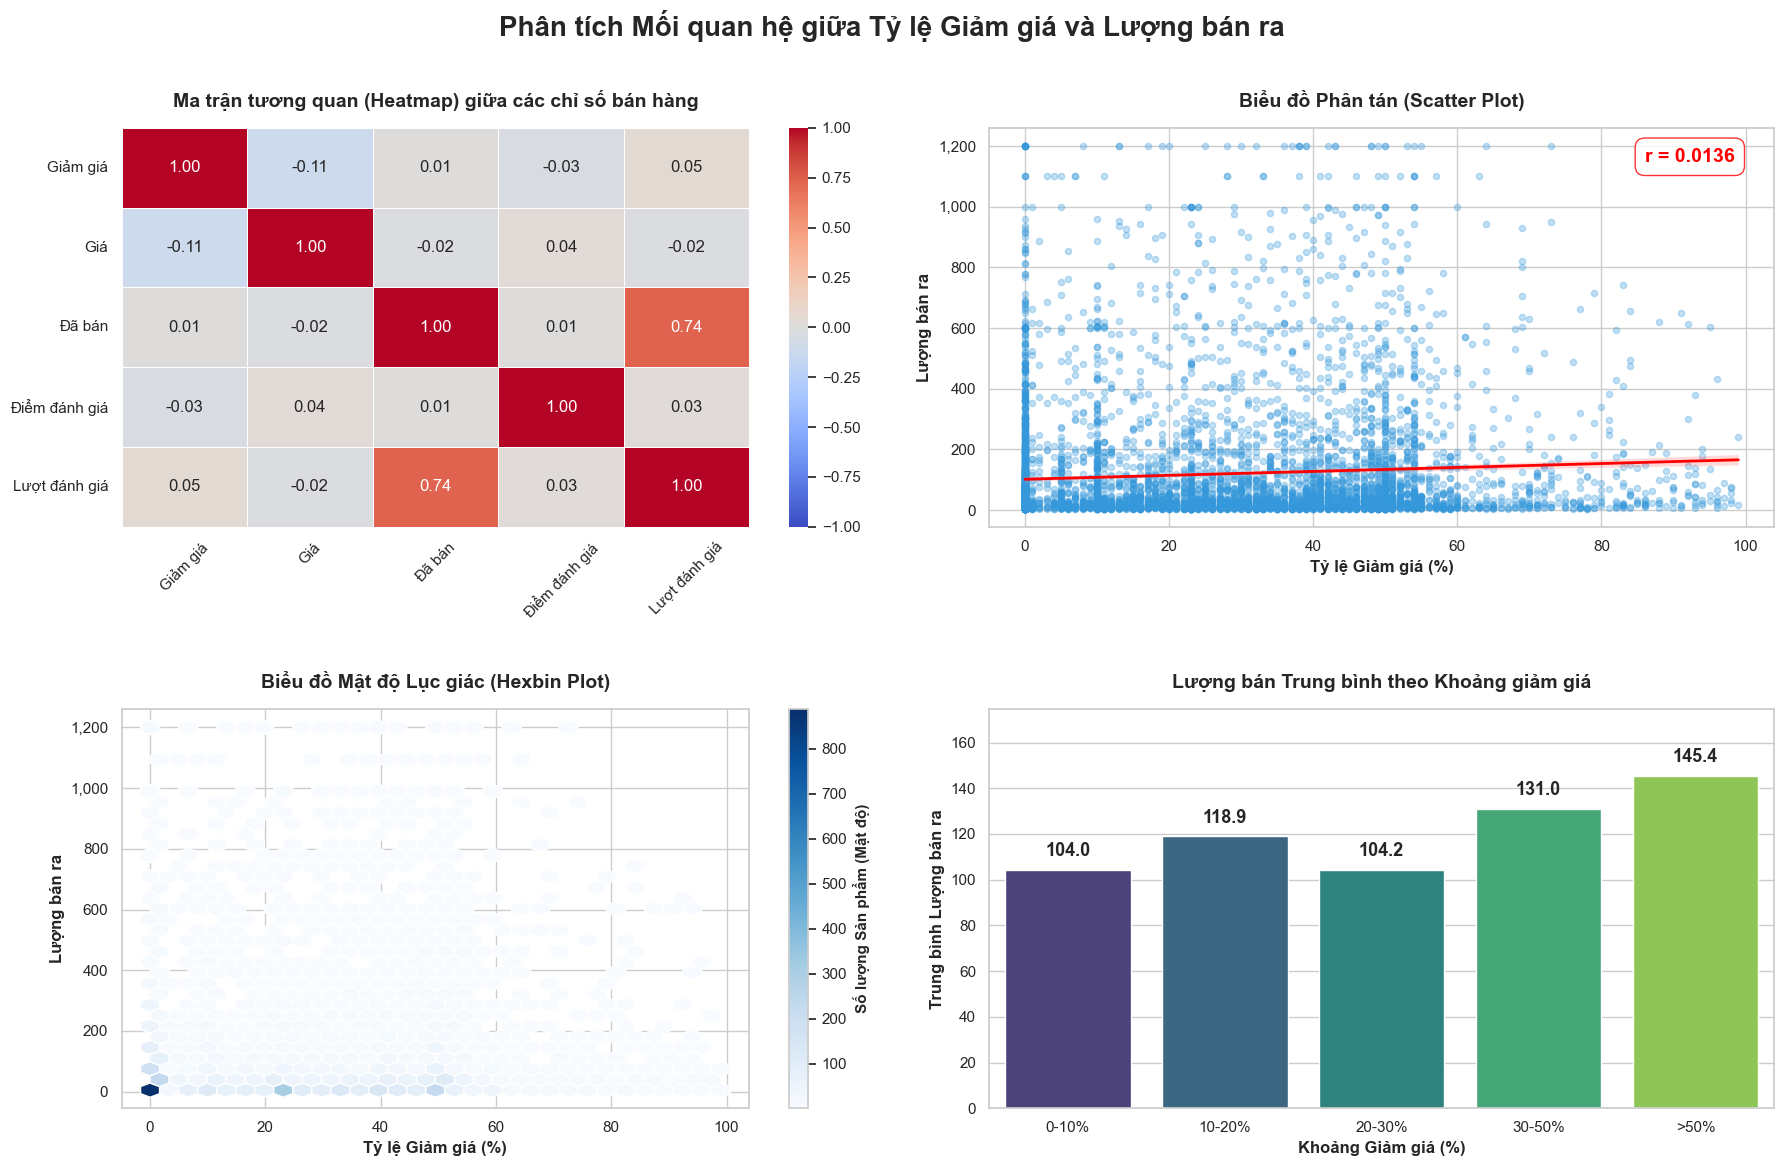

In [8]:
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")

pipeline_correlation = [
    {
        '$addFields': {
            'Giảm_giá_clean': {
                '$cond': [
                    {'$or': [{'$eq': ['$Giảm giá', None]}, {'$eq': ['$Giảm giá', '']}]},
                    0,
                    {
                        '$cond': [
                            {'$gte': [{'$toDouble': '$Giảm giá'}, 1]},
                            0.99,
                            {'$toDouble': '$Giảm giá'}
                        ]
                    }
                ]
            },
            'Giá_numeric': {'$toDouble': '$Giá'},
            'Đã_bán_numeric': {
                '$cond': [
                    {'$eq': ['$Đã bán', None]},
                    0,
                    {'$toDouble': '$Đã bán'}
                ]
            },
            'Điểm_đánh_giá_numeric': {
                '$cond': [
                    {'$eq': ['$Điểm đánh giá', None]},
                    0,
                    {'$toDouble': '$Điểm đánh giá'}
                ]
            },
            'Lượt_đánh_giá_numeric': {
                '$cond': [
                    {'$eq': ['$Lượt đánh giá', None]},
                    0,
                    {'$toDouble': '$Lượt đánh giá'}
                ]
            }
        }
    },
    {
        '$project': {
            '_id': 0,
            'Giảm_giá_clean': 1,
            'Giá_numeric': 1,
            'Đã_bán_numeric': 1,
            'Điểm_đánh_giá_numeric': 1,
            'Lượt_đánh_giá_numeric': 1
        }
    }
]

df_obj4 = pd.DataFrame(list(db['fact_products'].aggregate(pipeline_correlation)))

df_obj4 = df_obj4.rename(columns={
    'Giảm_giá_clean': 'Giảm giá',
    'Giá_numeric': 'Giá',
    'Đã_bán_numeric': 'Đã bán',
    'Điểm_đánh_giá_numeric': 'Điểm đánh giá',
    'Lượt_đánh_giá_numeric': 'Lượt đánh giá'
})

numeric_cols = df_obj4.select_dtypes(include=[np.number]).columns.tolist()

corr_matrix = df_obj4[numeric_cols].corr()

# Lấy hệ số r giữa Giảm giá và Đã bán
r_value = corr_matrix.loc['Giảm giá', 'Đã bán'] if 'Giảm giá' in corr_matrix.index else 0

# In kết quả kiểm chứng
print("="*60)
print(f"- Hệ số tương quan (r) giữa Giảm giá và Đã bán: {r_value:.4f}")
print("="*60)

df_corr = df_obj4.copy()

df_corr['Lượng bán ra'] = df_corr['Đã bán']
df_corr['Giảm giá (%)'] = df_corr['Giảm giá'] * 100

q95_sales = df_corr['Lượng bán ra'].quantile(0.95)
df_zoom = df_corr[df_corr['Lượng bán ra'] <= q95_sales].copy()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Phân tích Mối quan hệ giữa Tỷ lệ Giảm giá và Lượng bán ra', 
             fontsize=20, fontweight='bold', y=0.97)

# --- [GÓC TRÊN TRÁI] ĐỒ THỊ 1: HEATMAP ---
sns.heatmap(corr_matrix, 
            annot=True,          
            fmt=".2f",           
            cmap='coolwarm',     
            linewidths=0.5,      
            vmin=-1, vmax=1, ax=axes[0, 0])    

axes[0, 0].set_title('Ma trận tương quan (Heatmap) giữa các chỉ số bán hàng', fontsize=14, fontweight='bold', pad=15)
axes[0, 0].tick_params(axis='x', rotation=45, labelsize=11)
axes[0, 0].tick_params(axis='y', rotation=0, labelsize=11)

# --- [GÓC TRÊN PHẢI] ĐỒ THỊ 2: SCATTER PLOT ---
sns.regplot(data=df_zoom, x='Giảm giá (%)', y='Lượng bán ra', ax=axes[0, 1],
            scatter_kws={'alpha': 0.3, 'color': '#3498db', 's': 20},
            line_kws={'color': 'red', 'linewidth': 2})

axes[0, 1].set_title('Biểu đồ Phân tán (Scatter Plot)', fontsize=14, fontweight='bold', pad=15)
axes[0, 1].set_xlabel('Tỷ lệ Giảm giá (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Lượng bán ra', fontsize=12, fontweight='bold')
axes[0, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Ghi chú hệ số r
axes[0, 1].text(0.95, 0.95, f'r = {r_value:.4f}', transform=axes[0, 1].transAxes, 
             fontsize=14, fontweight='bold', color='red', ha='right', va='top',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='red', alpha=0.8))

# --- [GÓC DƯỚI TRÁI] ĐỒ THỊ 3: HEXBIN PLOT ---
hb = axes[1, 0].hexbin(df_zoom['Giảm giá (%)'], df_zoom['Lượng bán ra'], 
                    gridsize=30, cmap='Blues', edgecolors='white', mincnt=1)

axes[1, 0].set_title('Biểu đồ Mật độ Lục giác (Hexbin Plot)', fontsize=14, fontweight='bold', pad=15)
axes[1, 0].set_xlabel('Tỷ lệ Giảm giá (%)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Lượng bán ra', fontsize=12, fontweight='bold')
axes[1, 0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

cb = fig.colorbar(hb, ax=axes[1, 0])
cb.set_label('Số lượng Sản phẩm (Mật độ)', fontsize=11, fontweight='bold')

# --- [GÓC DƯỚI PHẢI] ĐỒ THỊ 4: BAR CHART ---
bins = [-1, 10, 20, 30, 50, 100]
labels = ['0-10%', '10-20%', '20-30%', '30-50%', '>50%']
df_zoom['Khoảng giảm giá'] = pd.cut(df_zoom['Giảm giá (%)'], bins=bins, labels=labels)
avg_sales = df_zoom.groupby('Khoảng giảm giá', observed=False)['Lượng bán ra'].mean().reset_index()

sns.barplot(data=avg_sales, x='Khoảng giảm giá', y='Lượng bán ra', 
            hue='Khoảng giảm giá', palette='viridis', legend=False, ax=axes[1, 1])

axes[1, 1].set_title('Lượng bán Trung bình theo Khoảng giảm giá', fontsize=14, fontweight='bold', pad=15)
axes[1, 1].set_xlabel('Khoảng Giảm giá (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Trung bình Lượng bán ra', fontsize=12, fontweight='bold')
axes[1, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

max_avg = avg_sales['Lượng bán ra'].max()
axes[1, 1].set_ylim(0, max_avg * 1.2)

for i, v in enumerate(avg_sales['Lượng bán ra']):
    axes[1, 1].text(i, v + (max_avg * 0.03), f'{v:,.1f}', ha='center', va='bottom', fontsize=13, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3.0, w_pad=2.0)
plt.show()


hexbij chuyển màu như heatmap 
### **Lý do chọn biểu đồ**
- Heatmap & Scatter/Hexbin Plot: Cung cấp minh chứng định lượng. Hệ số Pearson ($r$) và đường xu hướng (Trendline) giúp đo lường chính xác mức độ liên kết tuyến tính giữa biến "Giảm giá" và "Lượng bán ra" trên quy mô toàn thị trường.
- Bar Chart: Biểu đồ này so sánh trực tiếp hiệu quả bán hàng trung bình giữa các mốc chiết khấu, giúp hình dung rõ mức độ đánh đổi lợi nhuận.
### **Nhận xét**
- Dữ liệu từ Heatmap ghi nhận hệ số tương quan ở mức cực kỳ thấp ($r = 0.0136$).Con số này khẳng định tỷ lệ giảm giá và lượng bán ra gần như không có bất kỳ mối quan hệ tuyến tính nào.
- Biểu đồ phân tán minh chứng trực quan cho kết luận: các điểm dữ liệu phân bổ rộng khắp không theo một quỹ đạo nhất định, và đường xu hướng gần như nằm ngang hoàn toàn. Điều này có nghĩa là mức giảm giá thay đổi không làm lượng đơn hàng biến thiên theo tỷ lệ tương ứng.
- Biểu đồ cột làm rõ thêm rủi ro tài chính của việc lạm dụng khuyến mãi. Ngay cả khi nhà bán hàng thiết lập mức giảm giá kịch trần ($>50\%$), lượng bán trung bình cũng chỉ đạt 145.4 sản phẩm. Con số này chỉ nhích nhẹ so với mức 104.0 sản phẩm ở vùng chiết khấu rất thấp ($0 - 10\%$).

### **Kết luận**
-  Dữ liệu thống kê ($r = 0.0136$) khẳng định tỷ lệ giảm giá không tác động tuyến tính đến sức mua. Việc đẩy mức giảm lên quá cao chỉ mang lại số lượng đơn hàng tăng thêm rất khiêm tốn, nhưng lại bào mòn nghiêm trọng biên lợi nhuận của tổng thể gian hàng.
- Khi giá cả không còn là vũ khí thao túng được tâm lý khách hàng, các shop không nên áp dụng các mốc giảm giá sâu (>30%). Toàn bộ ngân sách trợ giá dư thừa nên được sang các kênh có tỷ lệ chuyển đổi thực chất hơn: Chạy quảng cáo tăng độ phủ, tối ưu SEO hình ảnh, hoặc nâng cấp uy tín gian hàng lên chuẩn LazMall.